# Choosing `max_gap_frames` (step 1.6): how long a hole is safe to repair?

Same idea as the visibility-threshold test, but for gap filling.

**Analogy:** a connect-the-dots drawing with some dots missing. Joining two dots that are close together with a ruler
is safe. If many dots are missing, the ruler line can cut across the real shape and we are just guessing.
So we need a *maximum hole length* above which we refuse to repair.

**The experiment (we know the right answer, so we can measure the damage):**
1. Take the real clip. After B's visibility mask, the arm is complete, so the angle at every frame is the **truth**.
2. Pretend one arm landmark was lost for `L` frames in a row, at many places in the clip.
3. Repair it with `fill_gaps`, recompute the elbow angle, and measure the error against the truth.
4. Repeat for `L = 1 ... 15`, plot the error, and pick the largest `L` whose error is acceptable.

## 1. Setup

In [1]:
import os, sys, subprocess
# Colab: get B's repo (this notebook needs angles.py, visibility.py and the .npy file). Locally: run from the repo folder.
if not os.path.exists("angles.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/suvini2001/AI-based-Physiotherapy-project-.git", "repo"], check=True)
    os.chdir("repo")
sys.path.insert(0, ".")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from visibility import mask_low_visibility, load_config
from angles import elbow_angle

try:
    from gap_fill import fill_gaps            # your file, once it is in the repo
except ImportError:                            # fallback copy so the notebook also runs on Colab before you push
    def _fill_1d(series, max_gap):
        s = series.copy(); is_nan = np.isnan(s)
        if not is_nan.any() or (~is_nan).sum() < 2: return s
        idx = np.arange(len(s)); good = ~is_nan
        line = np.interp(idx, idx[good], s[good])
        change = np.diff(np.concatenate([[False], is_nan, [False]]).astype(int))
        for a, b in zip(np.where(change == 1)[0], np.where(change == -1)[0]):
            if a == 0 or b == len(s): continue
            if (b - a) <= max_gap: s[a:b] = line[a:b]
        return s
    def fill_gaps(landmarks, max_gap=5):
        out = landmarks.copy()
        for j in range(out.shape[1]):
            for c in range(4): out[:, j, c] = _fill_1d(out[:, j, c], max_gap)
        return out

cfg = load_config()
data = np.load("data/elbow_A_landmarks.npy")           # (301, 33, 4)
masked = mask_low_visibility(data, cfg["visibility_threshold"])
truth = elbow_angle(masked)                            # right elbow, landmarks 12, 14, 16
FPS = 29.5                                             # real FPS of this clip (from README)
print("clip:", data.shape, "| angle NaN after mask:", int(np.isnan(truth).sum()),
      "| config max_gap_frames:", cfg["max_gap_frames"])

clip: (301, 33, 4) | angle NaN after mask: 0 | config max_gap_frames: 5


## 2. Run the experiment

For each hole length `L`, we remove (set to NaN, all 4 numbers, like B's mask does) one of the three arm landmarks
(shoulder 12, elbow 14, wrist 16) starting at many places in the clip, repair it, and record the angle error on every repaired frame.
We also record how fast the arm was moving at that frame, because straight-line repair is worst when the arm moves fast.

In [2]:
speed = np.abs(np.gradient(truth))                     # degrees per frame: how fast the arm moves
rows = []
for L in range(1, 16):
    for lm in (12, 14, 16):
        for start in range(3, len(masked) - L - 3, 2):
            holey = masked.copy()
            holey[start:start + L, lm, :] = np.nan
            repaired = elbow_angle(fill_gaps(holey, max_gap=L))      # allow exactly this hole length
            for k in range(start, start + L):
                rows.append((L, lm, start, k, abs(repaired[k] - truth[k]), speed[k]))
df = pd.DataFrame(rows, columns=["L", "landmark", "start", "frame", "error", "speed"])
print(len(df), "repaired frames measured")

51324 repaired frames measured


## 3. Plot: error against hole length

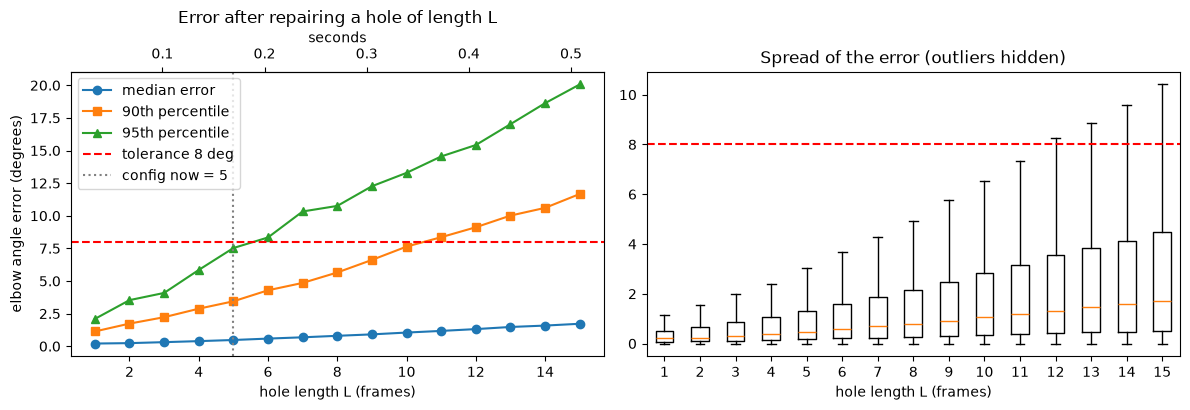

,median,90th pct,95th pct,calm median
L,,,,
1,0.2,1.1,2.1,0.2
2,0.2,1.7,3.5,0.2
3,0.3,2.2,4.1,0.3
4,0.4,2.9,5.8,0.4
5,0.5,3.4,7.5,0.4
6,0.6,4.3,8.3,0.5
7,0.7,4.9,10.3,0.6
8,0.8,5.7,10.8,0.7
9,0.9,6.6,12.3,0.8


In [3]:
fast = df.speed.quantile(0.90)                         # the fastest 10% of frames
calm = df[df.speed <= fast]
summary = pd.DataFrame({
    "median":      df.groupby("L").error.median(),
    "90th pct":    df.groupby("L").error.quantile(0.90),
    "95th pct":    df.groupby("L").error.quantile(0.95),
    "calm median": calm.groupby("L").error.median(),
})
TOL = 8.0   # degrees. Our choice: below the 9.36 deg 2D angle error the literature review reports for MediaPipe (P6),
            # so repair should add less error than the camera already has. Change it and re-run.

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = summary.index
ax[0].plot(x, summary["median"], "o-", label="median error")
ax[0].plot(x, summary["90th pct"], "s-", label="90th percentile")
ax[0].plot(x, summary["95th pct"], "^-", label="95th percentile")
ax[0].axhline(TOL, color="red", ls="--", label=f"tolerance {TOL:.0f} deg")
ax[0].axvline(cfg["max_gap_frames"], color="grey", ls=":", label=f"config now = {cfg['max_gap_frames']}")
ax[0].set_xlabel("hole length L (frames)"); ax[0].set_ylabel("elbow angle error (degrees)")
ax[0].set_title("Error after repairing a hole of length L"); ax[0].legend()
ax[1].boxplot([df[df.L == L].error for L in x], positions=x, showfliers=False)
ax[1].axhline(TOL, color="red", ls="--")
ax[1].set_xlabel("hole length L (frames)"); ax[1].set_title("Spread of the error (outliers hidden)")
secs = ax[0].secondary_xaxis("top", functions=(lambda f: f / FPS, lambda s: s * FPS)); secs.set_xlabel("seconds")
plt.tight_layout(); plt.savefig("data/gap_fill_choice.png", dpi=150); plt.show()
summary.round(1)

## 4. See what a repair looks like
Left: a short hole on a smooth part of the movement. Right: a long hole. The orange dashes are the repaired angle; the blue line is the truth.

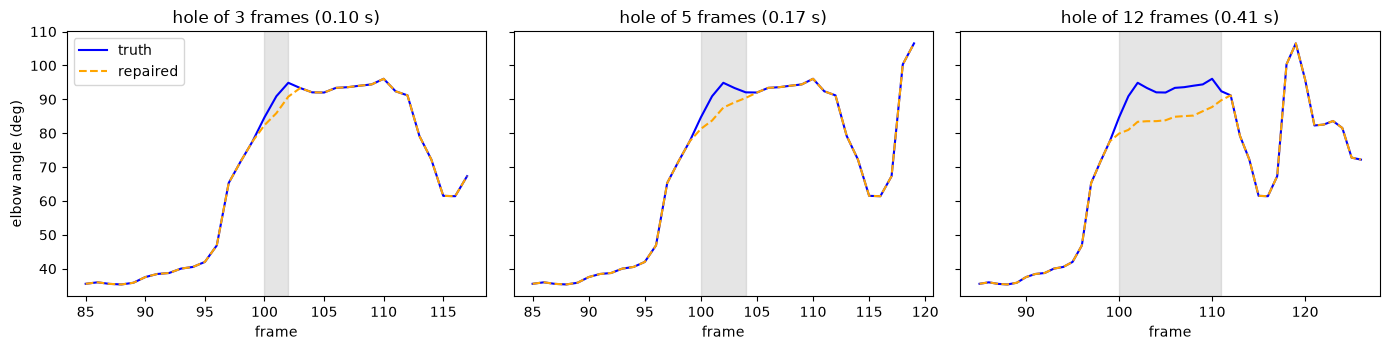

In [4]:
def example(L, start, lm=14):
    holey = masked.copy(); holey[start:start + L, lm, :] = np.nan
    return elbow_angle(fill_gaps(holey, max_gap=L))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, (L, start) in zip(ax, [(3, 100), (cfg["max_gap_frames"], 100), (12, 100)]):
    rep = example(L, start)
    sl = slice(start - 15, start + L + 15)
    a.plot(range(sl.start, sl.stop), truth[sl], "b-", label="truth")
    a.plot(range(sl.start, sl.stop), rep[sl], "--", color="orange", label="repaired")
    a.axvspan(start, start + L - 1, color="grey", alpha=0.2)
    a.set_title(f"hole of {L} frames ({L / FPS:.2f} s)"); a.set_xlabel("frame")
ax[0].set_ylabel("elbow angle (deg)"); ax[0].legend(); plt.tight_layout(); plt.show()

## 5. Pick the value
**Rule:** choose the largest `L` whose **95th-percentile error** is still below the tolerance. The median is tiny for every `L`,
so it is the rare bad cases (fast movement, or the arm pointing at the camera) that decide the limit.

In [5]:
ok = summary[summary["95th pct"] <= TOL]
best = int(ok.index.max()) if len(ok) else 0
print(f"Largest hole with 95th-percentile error <= {TOL:.0f} deg: {best} frames ({best / FPS:.2f} s)")
print(f"config.yaml currently says max_gap_frames: {cfg['max_gap_frames']}")
print("Try TOL = 5 or 10 above and watch how the answer moves: that is the safety margin.")

Largest hole with 95th-percentile error <= 8 deg: 5 frames (0.17 s)
config.yaml currently says max_gap_frames: 5
Try TOL = 5 or 10 above and watch how the answer moves: that is the safety margin.


## 6. Also check the real clip: how long are the actual holes?
In this clip the whole arm was visible, so there are no real arm holes. Run this cell on every new clip. If real holes are
usually longer than the chosen `max_gap_frames`, the clip has a tracking problem (lighting, clothing, arm hidden), and no gap length will fix it.

In [6]:
def gap_lengths(landmarks, idx):
    out = []
    for j in idx:
        isn = np.isnan(landmarks[:, j, 0]).astype(int)
        change = np.diff(np.concatenate([[0], isn, [0]]))
        out += list(np.where(change == -1)[0] - np.where(change == 1)[0])
    return out

arm_gaps = gap_lengths(masked, (12, 14, 16))
print("arm hole lengths in this clip (frames):", arm_gaps if arm_gaps else "none")

arm hole lengths in this clip (frames): none


## 7. Write down the decision
- Put the chosen value in `config.yaml` (`max_gap_frames`) and tell B.
- Add to the README: *"max_gap_frames = N chosen from `choose_max_gap.ipynb` (plot `data/gap_fill_choice.png`); tolerance 8 degrees, one easy clip, re-check with the protractor and on harder clips."*
- Limits to state honestly: one easy clip, one elbow, errors measured against MediaPipe's own angles (not a protractor).